# 05 - Ensemble Model: Random Forest
Loads the train data and preprocessor from notebook 00 and tests on `test_data.csv`.

In [1]:
import os, json, joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, ConfusionMatrixDisplay, classification_report)

SEED = 42
ROOT = os.path.abspath('..')
ART = os.path.join(ROOT, 'artifacts')

train = pd.read_csv(os.path.join(ART, 'train.csv'))
test = pd.read_csv(os.path.join(ROOT, 'test_data.csv'))
X_train, y_train = train.drop(columns='is_canceled'), train['is_canceled']
X_test, y_test = test.drop(columns='is_canceled'), test['is_canceled']
preprocessor = joblib.load(os.path.join(ART, 'preprocessor.joblib'))  # already fitted on train

## Model configuration
- 300 trees with `max_depth=20` and `min_samples_leaf=5`. Many trees together usually work better than one tree.
- `class_weight='balanced'` so the model gives more importance to the canceled class.

In [2]:
model = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(n_estimators=300, max_depth=20, min_samples_leaf=5,
                                   class_weight='balanced', n_jobs=-1, random_state=SEED)),
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

## Evaluation

Accuracy     0.8061
AUC          0.8956
Precision    0.6066
Recall       0.8220
F1           0.6981
MCC          0.5740
dtype: float64

              precision    recall  f1-score   support

           0     0.9230    0.8001    0.8572     12672
           1     0.6066    0.8220    0.6981      4752

    accuracy                         0.8061     17424
   macro avg     0.7648    0.8110    0.7776     17424
weighted avg     0.8367    0.8061    0.8138     17424



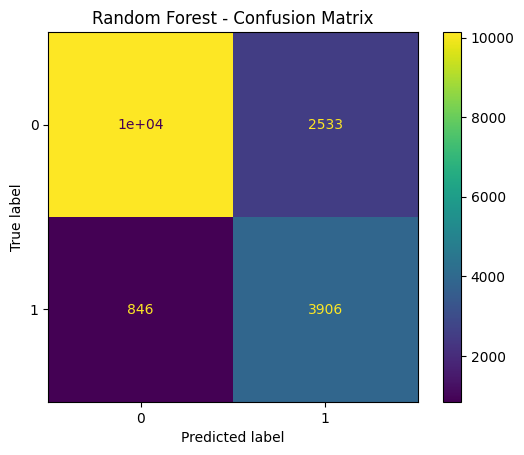

In [3]:
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'AUC': roc_auc_score(y_test, y_prob),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'MCC': matthews_corrcoef(y_test, y_pred),
}
metrics = {k: round(float(v), 4) for k, v in metrics.items()}
print(pd.Series(metrics))
print()
print(classification_report(y_test, y_pred, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [4]:
joblib.dump(model, os.path.join(ART, 'random_forest.joblib'), compress=3)
with open(os.path.join(ART, 'metrics_random_forest.json'), 'w') as f:
    json.dump({'model': 'Random Forest (Ensemble)', **metrics}, f, indent=2)
print('Saved model and metrics.')

Saved model and metrics.
